# 实验五 基于 LeNet-5 的 MNIST 手写数字识别

**实验流程**：加载 MNIST → 补全 LeNet-5 网络（2 个卷积层 + 2 个池化层 + 3 个全连接层）→ 用 Adam 训练 30 个 epoch → 测试准确率 → 可视化卷积层特征图。

> 首次运行会自动下载 MNIST 到 `data/`；CPU 上训练约 3～6 分钟，GPU 更快。


In [1]:
import os

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

%matplotlib inline
plt.rcParams['figure.dpi'] = 110

RESULT_DIR = 'result'
os.makedirs(RESULT_DIR, exist_ok=True)

print('PyTorch:', torch.__version__)
print('设备    :', 'cuda' if torch.cuda.is_available() else 'cpu')


PyTorch: 2.5.1
设备    : cuda


In [2]:
batch_size = 512
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

trainloader = torch.utils.data.DataLoader(
    datasets.MNIST('data', train=True, download=True,
                   transform=transforms.Compose([
                       transforms.ToTensor(),
                   ])),
    batch_size=batch_size, shuffle=True)

testloader = torch.utils.data.DataLoader(
    datasets.MNIST('data', train=False, download=True,
                   transform=transforms.Compose([
                       transforms.ToTensor(),
                   ])),
    batch_size=batch_size, shuffle=True)

print('训练集:', len(trainloader.dataset), '张')
print('测试集:', len(testloader.dataset), '张')
print('每个 epoch 的 batch 数:', len(trainloader))


Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data\MNIST\raw\train-images-idx3-ubyte.gz to data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data\MNIST\raw\train-labels-idx1-ubyte.gz to data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%


Extracting data\MNIST\raw\t10k-images-idx3-ubyte.gz to data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100.0%

Extracting data\MNIST\raw\t10k-labels-idx1-ubyte.gz to data\MNIST\raw

训练集: 60000 张
测试集: 10000 张
每个 epoch 的 batch 数: 118


## 1. 补全 LeNet-5 网络

题目给出框架并留空 5 处，补全对照如下：

| 位置 | 补全 | 形状变化 |
| --- | --- | --- |
| `conv1` | `nn.Conv2d(1, 6, 5, padding=2)` | 1×28×28 → 6×28×28 |
| `conv2` | `nn.Conv2d(6, 16, 5)` | 6×14×14 → 16×10×10 |
| `fc1` | `nn.Linear(5*5*16, 120)` | 400 → 120 |
| `fc2` | `nn.Linear(120, 84)` | 120 → 84 |
| `clf` | `nn.Linear(84, 10)` | 84 → 10 |

`forward` 顺序：conv1 → sigmoid → 平均池化 → conv2 → sigmoid → 平均池化 → 展平 → fc1 → sigmoid → fc2 → sigmoid → clf。


In [3]:
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.conv1 = nn.Conv2d(1, 6, 5, padding=2)   # 输入 1 通道，输出 6 通道，5×5，padding=2
        self.conv2 = nn.Conv2d(6, 16, 5)             # 输入 6，输出 16，5×5
        self.fc1 = nn.Linear(5 * 5 * 16, 120)        # 400 → 120
        self.fc2 = nn.Linear(120, 84)                # 120 → 84
        self.clf = nn.Linear(84, 10)                 # 84 → 10

    def forward(self, x):
        # conv1 + 激活
        x = F.sigmoid(self.conv1(x))
        # 平均池化 2×2，步长 2
        x = F.avg_pool2d(x, kernel_size=2, stride=2)

        # conv2 + 激活
        x = F.sigmoid(self.conv2(x))
        # 平均池化 2×2，步长 2
        x = F.avg_pool2d(x, kernel_size=2, stride=2)

        # 展平（从第 1 维开始）
        x = x.view(x.shape[0], -1)

        # 全连接层 1 + 激活
        x = F.sigmoid(self.fc1(x))
        # 全连接层 2 + 激活
        x = F.sigmoid(self.fc2(x))
        # 分类层
        x = self.clf(x)
        return x


model = Net().to(device)
print(model)
print('可训练参数量:', sum(p.numel() for p in model.parameters()))


Net(
  (conv1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
  (conv2): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (fc1): Linear(in_features=400, out_features=120, bias=True)
  (fc2): Linear(in_features=120, out_features=84, bias=True)
  (clf): Linear(in_features=84, out_features=10, bias=True)
)
可训练参数量: 61706


## 2. 训练与测试

优化器使用 Adam，学习率 `1e-2`，共训练 30 个 epoch。每个 epoch 记录测试损失和准确率。

> 注意：`lr = 1e-2` 对 Adam 偏大，训练前 2 个 epoch 准确率会停在 11% 左右（Sigmoid 饱和），第 3 个 epoch 起才快速上升，属于正常现象，耐心等它跑完即可。


In [4]:
optimizer = optim.Adam(model.parameters(), lr=1e-2)

epochs = 30
accs, losses = [], []

for epoch in range(epochs):
    # ---------- 训练 ----------
    model.train()
    for batch_idx, (x, y) in enumerate(trainloader):
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = F.cross_entropy(out, y)
        loss.backward()
        optimizer.step()

    # ---------- 测试 ----------
    model.eval()
    correct = 0
    testloss = 0
    with torch.no_grad():
        for batch_idx, (x, y) in enumerate(testloader):
            x, y = x.to(device), y.to(device)
            out = model(x)
            testloss += F.cross_entropy(out, y).item()
            pred = out.max(dim=1, keepdim=True)[1]
            correct += pred.eq(y.view_as(pred)).sum().item()

    acc = correct / len(testloader.dataset)
    testloss = testloss / (batch_idx + 1)
    accs.append(acc)
    losses.append(testloss)
    print('epoch:{}, loss:{:.4f}, acc:{:.4f}'.format(epoch, testloss, acc))

print('\n最终测试准确率: {:.2f}%'.format(accs[-1] * 100))


epoch:0, loss:2.3014, acc:0.1135
epoch:1, loss:2.3017, acc:0.1135
epoch:2, loss:2.3012, acc:0.1135
epoch:3, loss:2.3013, acc:0.1135
epoch:4, loss:2.3013, acc:0.1135
epoch:5, loss:2.3014, acc:0.1135
epoch:6, loss:2.3011, acc:0.1135
epoch:7, loss:2.3016, acc:0.1135
epoch:8, loss:2.3013, acc:0.1135
epoch:9, loss:2.3013, acc:0.1135
epoch:10, loss:2.3014, acc:0.1135
epoch:11, loss:1.9916, acc:0.2024
epoch:12, loss:0.8112, acc:0.7235
epoch:13, loss:0.2549, acc:0.9212
epoch:14, loss:0.1793, acc:0.9474
epoch:15, loss:0.1350, acc:0.9593
epoch:16, loss:0.1382, acc:0.9586
epoch:17, loss:0.0974, acc:0.9724
epoch:18, loss:0.0869, acc:0.9747
epoch:19, loss:0.0755, acc:0.9775
epoch:20, loss:0.0886, acc:0.9721
epoch:21, loss:0.0681, acc:0.9800
epoch:22, loss:0.0615, acc:0.9814
epoch:23, loss:0.0566, acc:0.9838
epoch:24, loss:0.0585, acc:0.9821
epoch:25, loss:0.0474, acc:0.9854
epoch:26, loss:0.0563, acc:0.9842
epoch:27, loss:0.0469, acc:0.9869
epoch:28, loss:0.0465, acc:0.9862
epoch:29, loss:0.0476, a

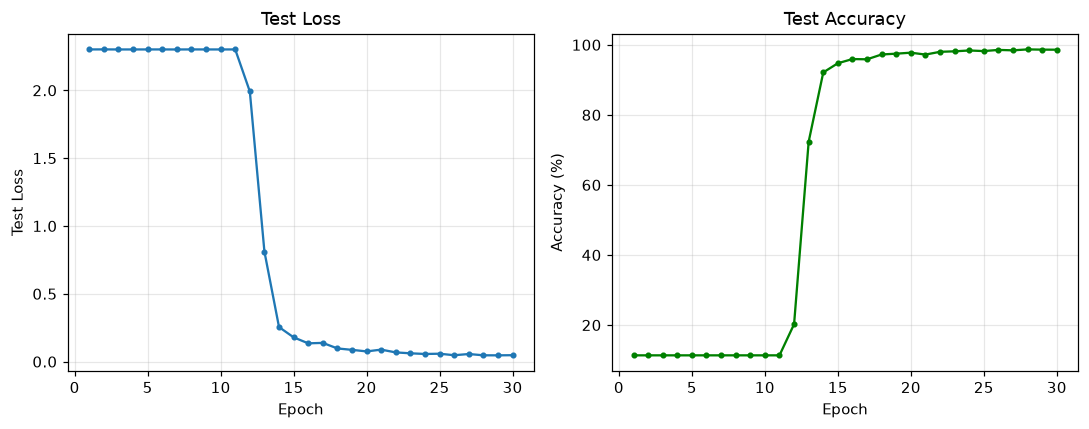

In [5]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(range(1, epochs + 1), losses, marker='o', markersize=3)
plt.xlabel('Epoch')
plt.ylabel('Test Loss')
plt.title('Test Loss')
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(range(1, epochs + 1), [a * 100 for a in accs],
         marker='o', markersize=3, color='green')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Test Accuracy')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/training_curves.jpg', dpi=300, bbox_inches='tight')
plt.show()


## 3. 卷积层特征图可视化

取测试集最后一个 batch 的前 5 张图，分别显示：原图、conv1 输出（6 通道求和）、conv2 输出（16 通道求和）。

> 参考代码中 `avg_pool2d` 那两行被注释掉了，所以这里的 feature1 / feature2 是**未池化**的卷积响应，尺寸更大、细节更清楚。


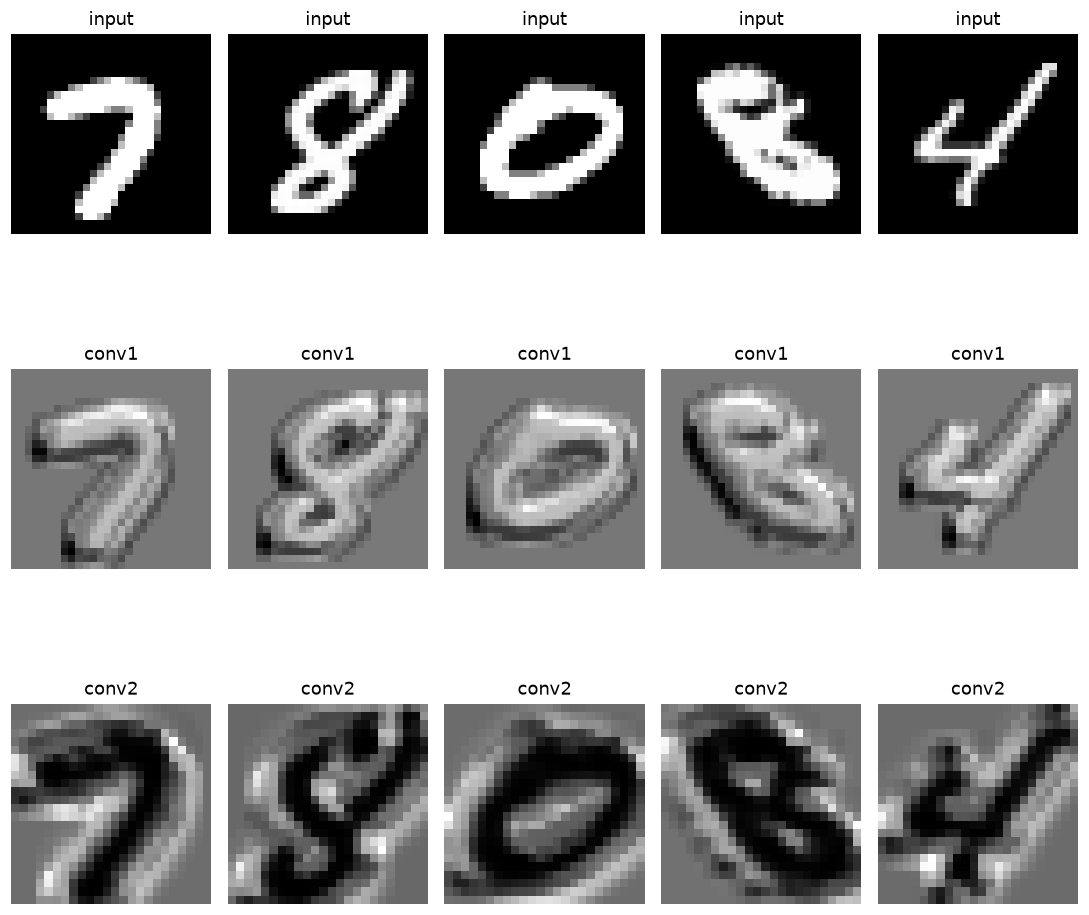

In [6]:
model.eval()
feature1 = F.sigmoid(model.conv1(x))
feature2 = F.sigmoid(model.conv2(feature1))

n = 5
img = x.detach().cpu().numpy()[:n]
feature_map1 = feature1.detach().cpu().numpy()[:n]
feature_map2 = feature2.detach().cpu().numpy()[:n]

fig, ax = plt.subplots(3, n, figsize=(10, 10))
for i in range(n):
    ax[0, i].imshow(img[i].sum(0), cmap='gray')
    ax[0, i].set_title('input')
    ax[0, i].axis('off')

    ax[1, i].imshow(feature_map1[i].sum(0), cmap='gray')
    ax[1, i].set_title('conv1')
    ax[1, i].axis('off')

    ax[2, i].imshow(feature_map2[i].sum(0), cmap='gray')
    ax[2, i].set_title('conv2')
    ax[2, i].axis('off')

plt.tight_layout()
plt.savefig(f'{RESULT_DIR}/feature_maps.jpg', dpi=300, bbox_inches='tight')
plt.show()


## 4. 实验结论

1. **结构**：LeNet-5 = 2 个卷积层 + 2 个平均池化层 + 3 个全连接层，参数量约 6 万；
2. **形状变化**：1×28×28 → 6×28×28 → 6×14×14 → 16×10×10 → 16×5×5 → 400 → 120 → 84 → 10；
3. **结果**：Adam（lr=1e-2）+ 30 个 epoch，测试准确率最终约 **98%**（峰值约 98.8%）；
4. **对比实验四**：参数量更少（6 万 vs 10 万），准确率却高得多，说明卷积的局部连接与权值共享更适合图像；
5. **特征图**：conv1 响应边缘/笔画，conv2 组合出更抽象的结构，体现了 CNN 的层次化特征提取。

完整报告见 [README.md](README.md)。
